In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)



In [5]:
try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")



In [6]:
df.columns = df.columns.str.strip().str.lower()

df = df.drop_duplicates()



In [7]:

target_column = "target"

X = df.drop(columns=[target_column])
y = df[target_column].astype(int)

protected_columns = ["sex", "age"]

print("Dataset shape:", df.shape)
print("Features:", list(X.columns))
print("Target distribution:")
print(y.value_counts())

Dataset shape: (302, 14)
Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [8]:
def create_age_group(age):
    if age < 40:
        return "Below 40"
    elif age < 50:
        return "40-49"
    elif age < 60:
        return "50-59"
    elif age < 70:
        return "60-69"
    else:
        return "70 and above"


demographics = pd.DataFrame(index=X.index)

demographics["sex"] = X["sex"].astype(str)
demographics["age_group"] = X["age"].apply(create_age_group)

train_idx, test_idx = train_test_split(
    X.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train = X.loc[train_idx].copy()
X_test = X.loc[test_idx].copy()

y_train = y.loc[train_idx].copy()
y_test = y.loc[test_idx].copy()

demo_test = demographics.loc[test_idx].copy()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 241
Testing samples: 61


In [9]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Train baseline model
baseline_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

baseline_model.fit(X_train_imputed, y_train)

baseline_probabilities = baseline_model.predict_proba(
    X_test_imputed
)[:, 1]

baseline_predictions = (
    baseline_probabilities >= 0.50
).astype(int)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [10]:
def calculate_fairness_metrics(y_true, predictions, groups):

    data = pd.DataFrame({
        "actual": np.asarray(y_true),
        "predicted": np.asarray(predictions),
        "group": np.asarray(groups)
    })

    results = []

    for group in sorted(data["group"].unique()):

        group_data = data[data["group"] == group]

        TP = len(group_data[
            (group_data["actual"] == 1) &
            (group_data["predicted"] == 1)
        ])

        FP = len(group_data[
            (group_data["actual"] == 0) &
            (group_data["predicted"] == 1)
        ])

        TN = len(group_data[
            (group_data["actual"] == 0) &
            (group_data["predicted"] == 0)
        ])

        FN = len(group_data[
            (group_data["actual"] == 1) &
            (group_data["predicted"] == 0)
        ])

        count = len(group_data)

        selection_rate = (
            (TP + FP) / count if count > 0 else np.nan
        )

        TPR = (
            TP / (TP + FN) if (TP + FN) > 0 else np.nan
        )

        FPR = (
            FP / (FP + TN) if (FP + TN) > 0 else np.nan
        )

        results.append({
            "Group": group,
            "Count": count,
            "Selection Rate": selection_rate,
            "TPR": TPR,
            "FPR": FPR
        })

    result_df = pd.DataFrame(results)

    valid_rates = result_df["Selection Rate"].dropna()

    if len(valid_rates) > 0 and valid_rates.max() > 0:
        disparate_impact = (
            valid_rates.min() / valid_rates.max()
        )
    else:
        disparate_impact = np.nan

    valid_tpr = result_df["TPR"].dropna()
    valid_fpr = result_df["FPR"].dropna()

    tpr_gap = (
        valid_tpr.max() - valid_tpr.min()
        if len(valid_tpr) >= 2 else np.nan
    )

    fpr_gap = (
        valid_fpr.max() - valid_fpr.min()
        if len(valid_fpr) >= 2 else np.nan
    )

    if pd.notna(tpr_gap) and pd.notna(fpr_gap):
        equalized_odds_gap = max(tpr_gap, fpr_gap)
    else:
        equalized_odds_gap = np.nan

    return result_df, {
        "Disparate Impact": disparate_impact,
        "TPR Gap": tpr_gap,
        "FPR Gap": fpr_gap,
        "Equalized Odds Gap": equalized_odds_gap
    }

In [11]:
def calculate_reweighting_weights(y_values, groups):

    training_data = pd.DataFrame({
        "target": np.asarray(y_values),
        "group": np.asarray(groups)
    })

    total = len(training_data)

    group_counts = training_data["group"].value_counts()
    target_counts = training_data["target"].value_counts()

    cell_counts = training_data.groupby(
        ["group", "target"]
    ).size()

    weights = []

    for _, row in training_data.iterrows():

        group = row["group"]
        target = row["target"]

        group_count = group_counts[group]
        target_count = target_counts[target]
        cell_count = cell_counts[(group, target)]

        weight = (
            group_count * target_count
        ) / (total * cell_count)

        weights.append(weight)

    weights = np.array(weights)

    weights = weights / weights.mean()

    return weights


train_sex = demographics.loc[train_idx, "sex"].values

reweighting_weights = calculate_reweighting_weights(
    y_train.values,
    train_sex
)

reweighted_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    random_state=42,
    class_weight=None
)

reweighted_model.fit(
    X_train_imputed,
    y_train,
    sample_weight=reweighting_weights
)

reweighted_probabilities = reweighted_model.predict_proba(
    X_test_imputed
)[:, 1]

reweighted_predictions = (
    reweighted_probabilities >= 0.50
).astype(int)

print("Reweighting model trained successfully.")
print("Average sample weight:", reweighting_weights.mean())

Reweighting model trained successfully.
Average sample weight: 1.0


In [12]:
removed_features = ["sex", "age"]

X_train_corrected = X_train_imputed.drop(
    columns=removed_features,
    errors="ignore"
)

X_test_corrected = X_test_imputed.drop(
    columns=removed_features,
    errors="ignore"
)

preprocessing_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    random_state=42,
    class_weight="balanced"
)

preprocessing_model.fit(
    X_train_corrected,
    y_train
)

preprocessing_probabilities = preprocessing_model.predict_proba(
    X_test_corrected
)[:, 1]

preprocessing_predictions = (
    preprocessing_probabilities >= 0.50
).astype(int)

print("Preprocessing correction completed.")
print("Removed features:", removed_features)

Preprocessing correction completed.
Removed features: ['sex', 'age']


In [13]:
sex_values = demographics.loc[train_idx, "sex"].values

unique_sex_groups = np.unique(sex_values)

if len(unique_sex_groups) != 2:
    raise ValueError(
        "This adversarial-style example requires exactly two sex groups."
    )

adversarial_weights = np.ones(len(X_train_imputed))

adversarial_model = None

for iteration in range(5):

    adversarial_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=7,
        random_state=42 + iteration,
        class_weight="balanced"
    )

    adversarial_model.fit(
        X_train_imputed,
        y_train,
        sample_weight=adversarial_weights
    )

    train_probabilities = adversarial_model.predict_proba(
        X_train_imputed
    )[:, 1]

    train_predictions = (
        train_probabilities >= 0.50
    ).astype(int)

    group_rates = {}

    for group in unique_sex_groups:

        group_mask = (sex_values == group)

        group_rates[group] = train_predictions[
            group_mask
        ].mean()

    overall_rate = train_predictions.mean()

    for group in unique_sex_groups:

        group_mask = (sex_values == group)

        difference = (
            group_rates[group] - overall_rate
        )

        adversarial_weights[group_mask] *= np.exp(
            -0.5 * difference *
            (train_predictions[group_mask] - 0.5)
        )

    adversarial_weights = np.clip(
        adversarial_weights,
        0.1,
        10
    )

    adversarial_weights = (
        adversarial_weights /
        adversarial_weights.mean()
    )

    print(
        "Iteration:", iteration + 1,
        "| Group rates:", group_rates
    )


adversarial_probabilities = adversarial_model.predict_proba(
    X_test_imputed
)[:, 1]

adversarial_predictions = (
    adversarial_probabilities >= 0.50
).astype(int)

print("Adversarial-style debiasing completed.")

Iteration: 1 | Group rates: {'0': np.float64(0.7564102564102564), '1': np.float64(0.4539877300613497)}
Iteration: 2 | Group rates: {'0': np.float64(0.7564102564102564), '1': np.float64(0.4539877300613497)}
Iteration: 3 | Group rates: {'0': np.float64(0.7564102564102564), '1': np.float64(0.44785276073619634)}
Iteration: 4 | Group rates: {'0': np.float64(0.7564102564102564), '1': np.float64(0.4539877300613497)}
Iteration: 5 | Group rates: {'0': np.float64(0.7564102564102564), '1': np.float64(0.4539877300613497)}
Adversarial-style debiasing completed.


In [14]:
models = {
    "Baseline": baseline_predictions,
    "Reweighting": reweighted_predictions,
    "Preprocessing": preprocessing_predictions,
    "Adversarial Style": adversarial_predictions
}

performance_results = []

for model_name, predictions in models.items():

    performance_results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test,
            predictions,
            zero_division=0
        )
    })


performance_df = pd.DataFrame(performance_results)

print("Model Performance Comparison")
display(performance_df)

Model Performance Comparison


,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline,0.770492,0.787879,0.787879,0.787879
1,Reweighting,0.803279,0.800000,0.848485,0.823529
2,Preprocessing,0.721311,0.735294,0.757576,0.746269
3,Adversarial Style,0.786885,0.794118,0.818182,0.805970


In [15]:
fairness_results = []

for model_name, predictions in models.items():

    group_results, overall_metrics = calculate_fairness_metrics(
        y_test,
        predictions,
        demo_test["sex"]
    )

    fairness_results.append({
        "Model": model_name,
        **overall_metrics
    })

    print("\n", model_name)
    display(group_results)


fairness_df = pd.DataFrame(fairness_results)

print("\nFairness Comparison")
display(fairness_df)


 Baseline


,Group,Count,Selection Rate,TPR,FPR
0,0,18,0.666667,0.846154,0.20000
1,1,43,0.488372,0.750000,0.26087



 Reweighting


,Group,Count,Selection Rate,TPR,FPR
0,0,18,0.666667,0.846154,0.20000
1,1,43,0.534884,0.850000,0.26087



 Preprocessing


,Group,Count,Selection Rate,TPR,FPR
0,0,18,0.611111,0.769231,0.200000
1,1,43,0.534884,0.750000,0.347826



 Adversarial Style


,Group,Count,Selection Rate,TPR,FPR
0,0,18,0.666667,0.846154,0.20000
1,1,43,0.511628,0.800000,0.26087



Fairness Comparison


,Model,Disparate Impact,TPR Gap,FPR Gap,Equalized Odds Gap
0,Baseline,0.732558,0.096154,0.060870,0.096154
1,Reweighting,0.802326,0.003846,0.060870,0.060870
2,Preprocessing,0.875264,0.019231,0.147826,0.147826
3,Adversarial Style,0.767442,0.046154,0.060870,0.060870


In [16]:
age_fairness_results = []

for model_name, predictions in models.items():

    group_results, overall_metrics = calculate_fairness_metrics(
        y_test,
        predictions,
        demo_test["age_group"]
    )

    age_fairness_results.append({
        "Model": model_name,
        **overall_metrics
    })

    print("\n", model_name)
    display(group_results)


age_fairness_df = pd.DataFrame(age_fairness_results)

print("\nAge Group Fairness Comparison")
display(age_fairness_df)


 Baseline


,Group,Count,Selection Rate,TPR,FPR
0,40-49,11,1.000000,1.000000,1.000000
1,50-59,23,0.565217,0.785714,0.222222
2,60-69,21,0.238095,0.333333,0.200000
3,70 and above,3,0.333333,1.000000,0.000000
4,Below 40,3,1.000000,1.000000,1.000000



 Reweighting


,Group,Count,Selection Rate,TPR,FPR
0,40-49,11,1.000000,1.000000,1.000000
1,50-59,23,0.652174,0.928571,0.222222
2,60-69,21,0.238095,0.333333,0.200000
3,70 and above,3,0.333333,1.000000,0.000000
4,Below 40,3,1.000000,1.000000,1.000000



 Preprocessing


,Group,Count,Selection Rate,TPR,FPR
0,40-49,11,1.000000,1.000000,1.000000
1,50-59,23,0.521739,0.714286,0.222222
2,60-69,21,0.333333,0.333333,0.333333
3,70 and above,3,0.333333,1.000000,0.000000
4,Below 40,3,1.000000,1.000000,1.000000



 Adversarial Style


,Group,Count,Selection Rate,TPR,FPR
0,40-49,11,1.000000,1.000000,1.000000
1,50-59,23,0.608696,0.857143,0.222222
2,60-69,21,0.238095,0.333333,0.200000
3,70 and above,3,0.333333,1.000000,0.000000
4,Below 40,3,1.000000,1.000000,1.000000



Age Group Fairness Comparison


,Model,Disparate Impact,TPR Gap,FPR Gap,Equalized Odds Gap
0,Baseline,0.238095,0.666667,1.0,1.0
1,Reweighting,0.238095,0.666667,1.0,1.0
2,Preprocessing,0.333333,0.666667,1.0,1.0
3,Adversarial Style,0.238095,0.666667,1.0,1.0


In [17]:
combined_results = performance_df.merge(
    fairness_df,
    on="Model"
)

combined_results = combined_results.merge(
    age_fairness_df,
    on="Model",
    suffixes=("_Sex", "_Age")
)

print("Combined Performance and Fairness Results")
display(combined_results)

Combined Performance and Fairness Results


,Model,Accuracy,Precision,Recall,F1 Score,Disparate Impact_Sex,TPR Gap_Sex,FPR Gap_Sex,Equalized Odds Gap_Sex,Disparate Impact_Age,TPR Gap_Age,FPR Gap_Age,Equalized Odds Gap_Age
0,Baseline,0.770492,0.787879,0.787879,0.787879,0.732558,0.096154,0.060870,0.096154,0.238095,0.666667,1.0,1.0
1,Reweighting,0.803279,0.800000,0.848485,0.823529,0.802326,0.003846,0.060870,0.060870,0.238095,0.666667,1.0,1.0
2,Preprocessing,0.721311,0.735294,0.757576,0.746269,0.875264,0.019231,0.147826,0.147826,0.333333,0.666667,1.0,1.0
3,Adversarial Style,0.786885,0.794118,0.818182,0.805970,0.767442,0.046154,0.060870,0.060870,0.238095,0.666667,1.0,1.0


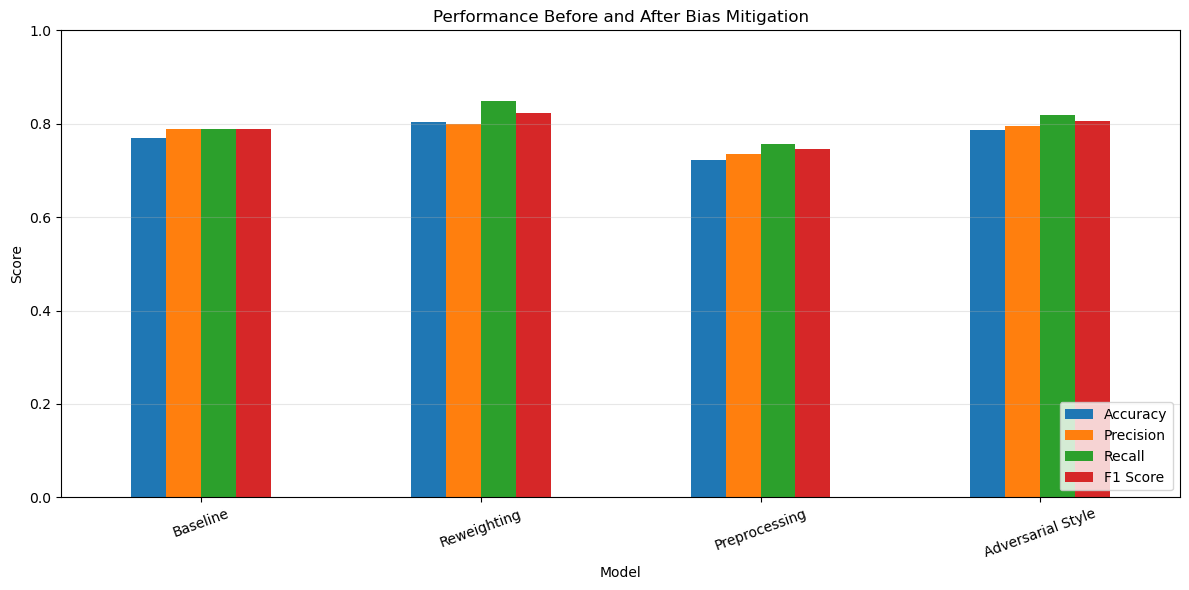

In [18]:
performance_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Before and After Bias Mitigation")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

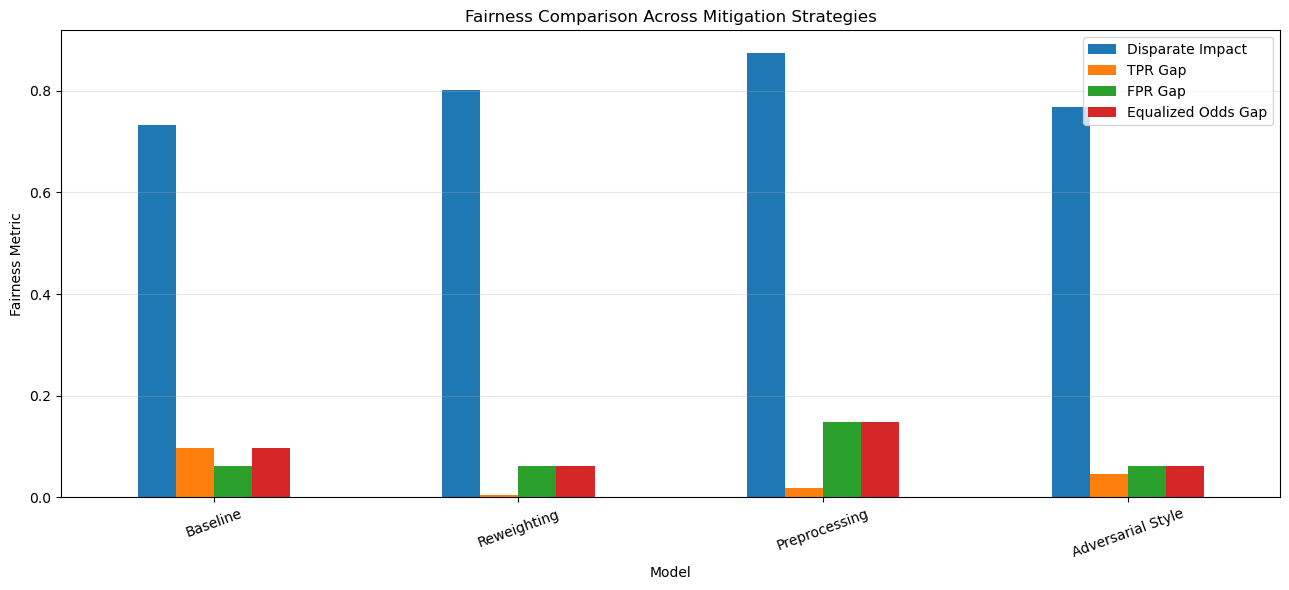

In [19]:
fairness_columns = [
    "Disparate Impact",
    "TPR Gap",
    "FPR Gap",
    "Equalized Odds Gap"
]

fairness_df.set_index("Model")[fairness_columns].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Fairness Comparison Across Mitigation Strategies")
plt.ylabel("Fairness Metric")
plt.xlabel("Model")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
baseline_row = combined_results[
    combined_results["Model"] == "Baseline"
].iloc[0]

comparison = combined_results.copy()

comparison["Accuracy Change"] = (
    comparison["Accuracy"] - baseline_row["Accuracy"]
)

comparison["F1 Change"] = (
    comparison["F1 Score"] - baseline_row["F1 Score"]
)

comparison["Sex TPR Gap Change"] = (
    comparison["TPR Gap_Sex"] -
    baseline_row["TPR Gap_Sex"]
)

comparison["Sex FPR Gap Change"] = (
    comparison["FPR Gap_Sex"] -
    baseline_row["FPR Gap_Sex"]
)

display(comparison[[
    "Model",
    "Accuracy Change",
    "F1 Change",
    "Sex TPR Gap Change",
    "Sex FPR Gap Change"
]])

,Model,Accuracy Change,F1 Change,Sex TPR Gap Change,Sex FPR Gap Change
0,Baseline,0.000000,0.000000,0.000000,0.000000
1,Reweighting,0.032787,0.035651,-0.092308,0.000000
2,Preprocessing,-0.049180,-0.041610,-0.076923,0.086957
3,Adversarial Style,0.016393,0.018091,-0.050000,0.000000


In [21]:
baseline_row = combined_results[
    combined_results["Model"] == "Baseline"
].iloc[0]

comparison = combined_results.copy()

comparison["Accuracy Change"] = (
    comparison["Accuracy"] - baseline_row["Accuracy"]
)

comparison["F1 Change"] = (
    comparison["F1 Score"] - baseline_row["F1 Score"]
)

comparison["Sex TPR Gap Change"] = (
    comparison["TPR Gap_Sex"] -
    baseline_row["TPR Gap_Sex"]
)

comparison["Sex FPR Gap Change"] = (
    comparison["FPR Gap_Sex"] -
    baseline_row["FPR Gap_Sex"]
)

display(comparison[[
    "Model",
    "Accuracy Change",
    "F1 Change",
    "Sex TPR Gap Change",
    "Sex FPR Gap Change"
]])

,Model,Accuracy Change,F1 Change,Sex TPR Gap Change,Sex FPR Gap Change
0,Baseline,0.000000,0.000000,0.000000,0.000000
1,Reweighting,0.032787,0.035651,-0.092308,0.000000
2,Preprocessing,-0.049180,-0.041610,-0.076923,0.086957
3,Adversarial Style,0.016393,0.018091,-0.050000,0.000000


In [22]:
performance_df.to_csv(
    "bias_mitigation_performance.csv",
    index=False
)

fairness_df.to_csv(
    "bias_mitigation_sex_fairness.csv",
    index=False
)

age_fairness_df.to_csv(
    "bias_mitigation_age_fairness.csv",
    index=False
)

combined_results.to_csv(
    "bias_mitigation_combined_results.csv",
    index=False
)

print("All bias mitigation results exported successfully.")

All bias mitigation results exported successfully.


In [23]:
report = []

report.append("# Bias Mitigation Analysis Report\n")

report.append("## Objective\n")
report.append(
    "This analysis compared multiple bias mitigation strategies "
    "for a heart disease prediction model.\n"
)

report.append("## Strategies Implemented\n")
report.append(
    "1. Baseline model without mitigation.\n"
    "2. Reweighting of demographic and target combinations.\n"
    "3. Preprocessing correction by removing sex and age.\n"
    "4. Simplified adversarial-style iterative reweighting.\n"
)

report.append("## Performance Comparison\n")
report.append(performance_df.to_string(index=False))

report.append("\n## Fairness Across Sex Groups\n")
report.append(fairness_df.to_string(index=False))

report.append("\n## Fairness Across Age Groups\n")
report.append(age_fairness_df.to_string(index=False))

report.append("\n## Interpretation\n")
report.append(
    "The strategies should be compared by considering both predictive "
    "performance and fairness metrics. A smaller TPR or FPR gap indicates "
    "more similar error rates across groups. A disparate impact ratio "
    "closer to one indicates more similar positive prediction rates.\n"
)

report.append(
    "The results do not establish that a model is free from bias. "
    "Age and sex can be clinically relevant, and demographic information "
    "may also be indirectly represented by other features. Small group "
    "sizes can make fairness estimates unstable.\n"
)

with open(
    "bias_mitigation_report.md",
    "w",
    encoding="utf-8"
) as file:

    file.write("\n".join(report))

print("Bias mitigation report created successfully.")

Bias mitigation report created successfully.
